# 02 — Preparación y modelado de datos

Fase 3 del proyecto. Aquí diagnosticamos la calidad de los datos, los limpiamos y transformamos, seleccionamos las variables y construimos el modelo dimensional (tablas de hechos y dimensiones) que usa el dashboard de Power BI.

## 1. Diagnóstico de calidad de los datos

Antes de limpiar, necesitamos saber qué problemas tienen los datos y cómo pueden afectar las decisiones de una productora: cuánto invertir, cuándo estrenar y qué tipo de película producir. En esta sección cuantificamos los problemas, revisamos casos concretos y proponemos su tratamiento.

Trabajamos con los dos archivos originales de **TMDB 5000 Movie Dataset** disponibles en `data/raw/`. Leemos directamente estos archivos para que el diagnóstico se pueda ejecutar sin depender de variables o resultados de otros notebooks. Las conversiones y los filtros de esta sección son auxiliares para medir la calidad: conservamos las tablas originales y todavía no exportamos datos procesados.

Usamos revisión de faltantes, tipos e integridad, junto con boxplots y rango intercuartílico (IQR). Estas herramientas se relacionan con la preparación de datos y la estadística descriptiva estudiadas en las semanas 3 y 4. Un valor atípico es una señal para revisar; por sí solo no demuestra un error.

### 1.1 Carga y estructura

Cada fila del archivo de películas describe una película. En créditos, cada fila contiene su reparto y equipo técnico. La correspondencia se establece entre `movies.id` y `credits.movie_id`; el título sirve para consultar los casos, pero no como llave de unión.

Las rutas funcionan al abrir el notebook desde `notebooks/` o desde la raíz del repositorio. Si no encontramos ambos archivos originales, detenemos la carga con un mensaje explícito.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

ARCHIVOS = ("tmdb_5000_movies.csv.zip", "tmdb_5000_credits.csv.zip")
candidatas = (Path("../data/raw"), Path("data/raw"))
RAW = next((carpeta for carpeta in candidatas
            if all((carpeta / nombre).is_file() for nombre in ARCHIVOS)), None)
if RAW is None:
    raise FileNotFoundError(
        "No encontramos los dos ZIP originales en data/raw. "
        "Ejecutamos este notebook desde notebooks/ o desde la raíz del proyecto."
    )

movies = pd.read_csv(RAW / ARCHIVOS[0], low_memory=False)
credits = pd.read_csv(RAW / ARCHIVOS[1], low_memory=False)
N = len(movies)

# Conservamos una referencia para comprobar al final que el diagnóstico no altera las tablas.
movies_original = movies.copy(deep=True)
credits_original = credits.copy(deep=True)

estructura = pd.DataFrame({
    "archivo": ARCHIVOS,
    "filas": [len(movies), len(credits)],
    "columnas": [movies.shape[1], credits.shape[1]],
    "llave": ["id", "movie_id"],
})
display(estructura)

,archivo,filas,columnas,llave
0,tmdb_5000_movies.csv.zip,4803,20,id
1,tmdb_5000_credits.csv.zip,4803,4,movie_id


In [2]:
numericas_esperadas = ["id", "budget", "revenue", "runtime", "popularity",
                      "vote_average", "vote_count"]
json_movies = ["genres", "keywords", "production_companies",
               "production_countries", "spoken_languages"]
json_credits = ["cast", "crew"]

tipo_esperado = {col: "Texto" for col in movies.columns}
tipo_esperado.update({col: "Numérico" for col in numericas_esperadas})
tipo_esperado.update({col: "Lista de objetos en JSON" for col in json_movies})
tipo_esperado["release_date"] = "Fecha YYYY-MM-DD"
display(pd.DataFrame({
    "tipo_leído": movies.dtypes.astype(str),
    "contenido_esperado": pd.Series(tipo_esperado),
}).rename_axis("variable"))
display(pd.DataFrame({
    "tipo_leído": credits.dtypes.astype(str),
    "contenido_esperado": pd.Series({"movie_id": "Identificador entero",
                                    "title": "Texto", "cast": "Lista en JSON",
                                    "crew": "Lista en JSON"}),
}).rename_axis("variable"))

# Convertimos en una tabla auxiliar para detectar valores no interpretables como números.
numericas = movies[numericas_esperadas].apply(pd.to_numeric, errors="coerce")
errores_numericos = movies[numericas_esperadas].notna() & numericas.isna()
display(errores_numericos.sum().rename("valores_no_convertibles").to_frame())

,tipo_leído,contenido_esperado
variable,,
budget,int64,Numérico
genres,str,Lista de objetos en JSON
homepage,str,Texto
id,int64,Numérico
keywords,str,Lista de objetos en JSON
original_language,str,Texto
original_title,str,Texto
overview,str,Texto
popularity,float64,Numérico


,tipo_leído,contenido_esperado
variable,,
movie_id,int64,Identificador entero
title,str,Texto
cast,str,Lista en JSON
crew,str,Lista en JSON


,valores_no_convertibles
id,0
budget,0
revenue,0
runtime,0
popularity,0
vote_average,0
vote_count,0


**Interpretación.** La fuente que usamos contiene 4.803 películas, 20 columnas de metadatos y cuatro columnas en créditos. En estos archivos las variables numéricas revisadas se convierten sin errores. `release_date` se recibe como texto, algo esperable al leer un CSV, y lo verificamos como fecha más adelante. Los campos JSON necesitan una revisión de su contenido: tener un texto no nulo no garantiza que la lista contenga información.

### 1.2 Completitud: nulos, ceros y campos vacíos

Primero contamos los nulos tal como los reconoce pandas. También buscamos textos vacíos o compuestos solo por espacios. El porcentaje usa como denominador todas las filas de cada archivo. Después revisamos por separado los ceros y las listas vacías, porque `isna()` no los detecta.

In [3]:
def resumen_completitud(tabla):
    vacios = tabla.apply(lambda serie: serie.map(
        lambda valor: isinstance(valor, str) and not valor.strip()).sum())
    resumen = pd.DataFrame({"nulos": tabla.isna().sum(), "textos_vacíos": vacios})
    resumen["% nulos"] = (resumen["nulos"] / len(tabla) * 100).round(2)
    resumen["% textos vacíos"] = (resumen["textos_vacíos"] / len(tabla) * 100).round(2)
    return resumen.sort_values("nulos", ascending=False).rename_axis("variable")

display(Markdown("**Películas**"))
display(resumen_completitud(movies))
display(Markdown("**Créditos**"))
display(resumen_completitud(credits))

variables_cero = ["budget", "revenue", "runtime"]
resumen_ceros = pd.DataFrame({
    "nulos_originales": movies[variables_cero].isna().sum(),
    "no_convertibles": errores_numericos[variables_cero].sum(),
    "ceros": numericas[variables_cero].eq(0).sum(),
})
resumen_ceros["% ceros"] = (resumen_ceros["ceros"] / N * 100).round(2)
resumen_ceros["ausentes_o_cero"] = (
    numericas[variables_cero].isna() | numericas[variables_cero].eq(0)).sum()
resumen_ceros["% ausentes o cero"] = (resumen_ceros["ausentes_o_cero"] / N * 100).round(2)
display(resumen_ceros)

**Películas**

,nulos,textos_vacíos,% nulos,% textos vacíos
variable,,,,
homepage,3091,0,64.36,0.00
tagline,844,0,17.57,0.00
overview,3,1,0.06,0.02
runtime,2,0,0.04,0.00
release_date,1,0,0.02,0.00
id,0,0,0.00,0.00
budget,0,0,0.00,0.00
genres,0,0,0.00,0.00
original_title,0,0,0.00,0.00


**Créditos**

,nulos,textos_vacíos,% nulos,% textos vacíos
variable,,,,
movie_id,0,0,0.0,0.0
title,0,0,0.0,0.0
cast,0,0,0.0,0.0
crew,0,0,0.0,0.0


,nulos_originales,no_convertibles,ceros,% ceros,ausentes_o_cero,% ausentes o cero
budget,0,0,1037,21.59,1037,21.59
revenue,0,0,1427,29.71,1427,29.71
runtime,2,0,35,0.73,37,0.77


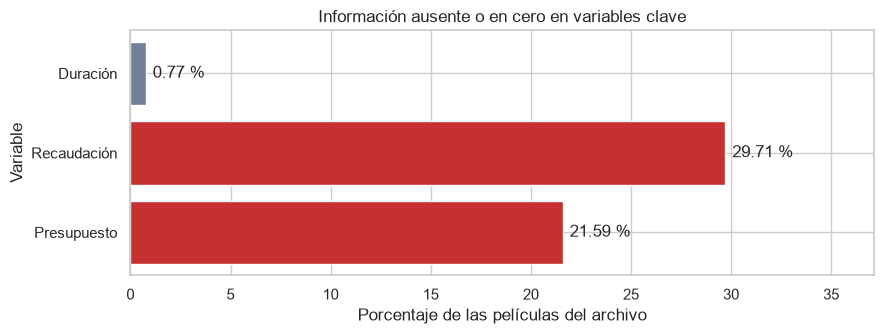

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
porcentajes = resumen_ceros["% ausentes o cero"]
barras = ax.barh(["Presupuesto", "Recaudación", "Duración"], porcentajes,
                color=["#c53030", "#c53030", "#718096"])
ax.bar_label(barras, labels=[f"{valor:.2f} %" for valor in porcentajes], padding=5)
ax.set_xlim(0, max(porcentajes.max() * 1.25, 5))
ax.set_title("Información ausente o en cero en variables clave")
ax.set_xlabel("Porcentaje de las películas del archivo")
ax.set_ylabel("Variable")
plt.tight_layout()
plt.show()

**Interpretación.** Encontramos 1.037 presupuestos en cero (21,59 %) y 1.427 recaudaciones en cero (29,71 %). La duración tiene 35 ceros y dos nulos: 37 registros requieren atención. Para el análisis financiero proponemos tratar los montos en cero como información no reportada, explicitando que el archivo no permite verificar individualmente qué significa cada cero. Incluirlos como pérdidas reales o dividir por un presupuesto cero distorsionaría el retorno.

La ausencia de una página web o una frase promocional no justifica eliminar una película de un análisis financiero. El tratamiento debe depender de las variables necesarias para cada pregunta. Tampoco sumamos los problemas de distintas columnas para contar películas afectadas, porque una misma película puede tener más de un problema.

### 1.3 Contenido de las columnas JSON

Comprobamos si cada campo puede leerse con `json.loads`, si contiene una lista y si sus elementos tienen los campos básicos esperados. Diferenciamos ausencia del campo, lista vacía, texto inválido y estructura inesperada. Esta revisión no transforma ni reemplaza las columnas originales.

In [5]:
def estado_json(valor, campos):
    if pd.isna(valor) or (isinstance(valor, str) and not valor.strip()):
        return "ausente"
    try:
        contenido = json.loads(valor)
    except (TypeError, ValueError):
        return "JSON inválido"
    if not isinstance(contenido, list):
        return "estructura inesperada"
    if not contenido:
        return "lista vacía"
    if not all(isinstance(elemento, dict) and campos.issubset(elemento)
               for elemento in contenido):
        return "estructura inesperada"
    return "lista con datos"

estados = ["ausente", "JSON inválido", "estructura inesperada", "lista vacía", "lista con datos"]
revisiones_json = []
ejemplos_json = []
for nombre, tabla, columnas, llave in [
    ("películas", movies, json_movies, "id"),
    ("créditos", credits, json_credits, "movie_id"),
]:
    for columna in columnas:
        campos = {"iso_3166_1", "name"} if columna == "production_countries" else {"id", "name"}
        if columna == "spoken_languages":
            campos = {"iso_639_1", "name"}
        if columna == "crew":
            campos = {"id", "name", "job"}
        revision = tabla[columna].map(lambda valor: estado_json(valor, campos))
        conteo = revision.value_counts().reindex(estados, fill_value=0)
        revisiones_json.append({"archivo": nombre, "columna": columna,
                                **conteo.to_dict(),
                                "% listas vacías": round(conteo["lista vacía"] / len(tabla) * 100, 2)})
        for indice in revision[revision != "lista con datos"].head(2).index:
            ejemplos_json.append({"archivo": nombre, "columna": columna,
                                  "id": tabla.at[indice, llave], "título": tabla.at[indice, "title"],
                                  "estado": revision.at[indice]})

resumen_json = pd.DataFrame(revisiones_json)
display(resumen_json)
display(pd.DataFrame(ejemplos_json))

,archivo,columna,ausente,JSON inválido,estructura inesperada,lista vacía,lista con datos,% listas vacías
0,películas,genres,0,0,0,28,4775,0.58
1,películas,keywords,0,0,0,412,4391,8.58
2,películas,production_companies,0,0,0,351,4452,7.31
3,películas,production_countries,0,0,0,174,4629,3.62
4,películas,spoken_languages,0,0,0,86,4717,1.79
5,créditos,cast,0,0,0,43,4760,0.90
6,créditos,crew,0,0,0,28,4775,0.58


,archivo,columna,id,título,estado
0,películas,genres,191229,Iguana,lista vacía
1,películas,genres,346081,Sardaarji,lista vacía
2,películas,keywords,1735,The Mummy: Tomb of the Dragon Emperor,lista vacía
3,películas,keywords,79698,The Lovers,lista vacía
4,películas,production_companies,53953,The Tooth Fairy,lista vacía
5,películas,production_companies,45054,There Be Dragons,lista vacía
6,películas,production_countries,24113,Town & Country,lista vacía
7,películas,production_countries,53953,The Tooth Fairy,lista vacía
8,películas,spoken_languages,293644,Top Cat Begins,lista vacía
9,películas,spoken_languages,109410,42,lista vacía


**Interpretación.** Las siete columnas revisadas contienen JSON válido y cumplen la estructura básica comprobada. Sin embargo, hay 28 listas vacías de géneros, 351 de productoras, 174 de países, 86 de idiomas hablados, 412 de palabras clave, 43 de reparto y 28 de equipo técnico.

Una lista de géneros vacía limita la segmentación por género; una lista de equipo técnico vacía limita el análisis de talento. No implica necesariamente que la película deba salir del análisis financiero. Que el JSON sea válido tampoco confirma que todas las personas, empresas o categorías estén completas o correctamente registradas.

### 1.4 Duplicados e integridad entre películas y créditos

Revisamos duplicados exactos y por llave. Contamos tanto repeticiones adicionales como todas las filas involucradas en una llave repetida. Luego verificamos identificadores enteros positivos y comparamos su cobertura entre archivos antes de proponer cualquier unión.

In [6]:
resumen_duplicados = []
ids_validos = {}
for nombre, tabla, llave in [("películas", movies, "id"), ("créditos", credits, "movie_id")]:
    ids = pd.to_numeric(tabla[llave], errors="coerce")
    validos = ids.notna() & np.isfinite(ids) & ids.gt(0) & ids.mod(1).eq(0)
    ids_validos[nombre] = set(ids[validos].astype("int64"))
    resumen_duplicados.append({
        "archivo": nombre,
        "filas_duplicadas_adicionales": int(tabla.duplicated().sum()),
        "llaves_repetidas_adicionales": int(tabla[llave].duplicated().sum()),
        "filas_con_llave_repetida": int(tabla[llave].duplicated(keep=False).sum()),
        "identificadores_inválidos": int((~validos).sum()),
        "identificadores_válidos_únicos": len(ids_validos[nombre]),
    })

display(pd.DataFrame(resumen_duplicados))
ids_movies, ids_credits = ids_validos["películas"], ids_validos["créditos"]
display(pd.Series({
    "Identificadores en ambos archivos": len(ids_movies & ids_credits),
    "Películas sin registro de créditos": len(ids_movies - ids_credits),
    "Créditos sin registro de película": len(ids_credits - ids_movies),
}, name="cantidad").to_frame())

titulos_repetidos = movies["title"].notna() & movies["title"].duplicated(keep=False)
display(movies.loc[titulos_repetidos, ["id", "title", "release_date"]].sort_values(["title", "release_date"]))

,archivo,filas_duplicadas_adicionales,llaves_repetidas_adicionales,filas_con_llave_repetida,identificadores_inválidos,identificadores_válidos_únicos
0,películas,0,0,0,0,4803
1,créditos,0,0,0,0,4803


,cantidad
Identificadores en ambos archivos,4803
Películas sin registro de créditos,0
Créditos sin registro de película,0


,id,title,release_date
4267,2661,Batman,1966-07-30
1359,268,Batman,1989-06-23
3647,39269,Out of the Blue,1980-05-01
3693,10844,Out of the Blue,2006-10-12
2877,1255,The Host,2006-07-27
972,72710,The Host,2013-03-22


**Interpretación.** No encontramos duplicados exactos, llaves repetidas ni identificadores inválidos. Los 4.803 identificadores aparecen en ambos archivos, por lo que una futura unión por `id` y `movie_id` debería conservar una fila por película. Recomendamos comprobarlo con `validate="one_to_one"` cuando se implemente esa unión.

Los títulos repetidos corresponden a identificadores y fechas diferentes, como las dos películas tituladas *Batman*. Por eso no proponemos eliminar registros por título. La existencia de una fila en créditos tampoco garantiza que su reparto o equipo técnico estén informados: eso lo medimos en la revisión del JSON.

### 1.5 Fechas, estados y rangos

Separamos fechas ausentes de textos que no se pueden interpretar como fecha. Revisamos también el estado de producción y reglas básicas de validez. No imponemos un límite arbitrario a una duración alta ni a una recaudación grande: esos casos se examinan como atípicos.

In [7]:
fecha_ausente = movies["release_date"].isna() | movies["release_date"].fillna("").str.strip().eq("")
fechas = pd.to_datetime(movies["release_date"], format="%Y-%m-%d", errors="coerce")
fecha_invalida = ~fecha_ausente & fechas.isna()
display(pd.Series({
    "Fechas ausentes": int(fecha_ausente.sum()),
    "Fechas presentes pero inválidas": int(fecha_invalida.sum()),
    "Fecha mínima interpretable": fechas.min().date(),
    "Fecha máxima interpretable": fechas.max().date(),
}, name="resultado").to_frame())
display(movies.loc[fechas.isna(), ["id", "title", "release_date", "status"]])

estados_peliculas = movies["status"].value_counts(dropna=False).rename("películas").to_frame()
estados_peliculas["% del total"] = (estados_peliculas["películas"] / N * 100).round(2)
display(estados_peliculas)
no_estrenadas = movies["status"].ne("Released") | movies["status"].isna()
display(movies.loc[no_estrenadas, ["id", "title", "status", "release_date", "budget", "revenue"]])

,resultado
Fechas ausentes,1
Fechas presentes pero inválidas,0
Fecha mínima interpretable,1916-09-04
Fecha máxima interpretable,2017-02-03


,id,title,release_date,status
4553,380097,America Is Still the Place,NaN,Released


,películas,% del total
status,,
Released,4795,99.83
Rumored,5,0.10
Post Production,3,0.06


,id,title,status,release_date,budget,revenue
2906,357837,Dancin' It's On,Post Production,2015-10-16,0,0
4169,295886,Brotherly Love,Post Production,2015-04-24,1900000,0
4178,50875,Higher Ground,Post Production,2011-08-26,2000000,841733
4401,43630,The Helix... Loaded,Rumored,2005-01-01,0,0
4453,57294,Crying with Laughter,Rumored,2009-06-01,0,0
4508,70875,The Harvest (La Cosecha),Rumored,2011-07-29,56000,0
4662,40963,Little Big Top,Rumored,2006-01-01,0,0
4754,84659,The Naked Ape,Rumored,2006-09-16,0,0


In [8]:
reglas = {f"{col}: valor negativo": numericas[col].lt(0)
          for col in ["budget", "revenue", "runtime", "popularity", "vote_count"]}
reglas["vote_average: fuera de 0 a 10"] = (
    numericas["vote_average"].notna() & ~numericas["vote_average"].between(0, 10))
reglas["vote_count: número no entero"] = (
    numericas["vote_count"].notna() & numericas["vote_count"].mod(1).ne(0))
for col in numericas_esperadas:
    reglas[f"{col}: valor infinito"] = numericas[col].notna() & ~np.isfinite(numericas[col])

display(pd.Series({regla: int(mascara.sum()) for regla, mascara in reglas.items()},
                  name="filas_señaladas").to_frame())
con_problema_rango = pd.DataFrame(reglas).any(axis=1)
display(movies.loc[con_problema_rango, ["id", "title"] + numericas_esperadas[1:]])

display(pd.Series({
    "Películas con cero votos": int(numericas["vote_count"].eq(0).sum()),
    "Calificación cero con votos positivos": int((numericas["vote_average"].eq(0)
                                                   & numericas["vote_count"].gt(0)).sum()),
}, name="películas").to_frame())

,filas_señaladas
budget: valor negativo,0
revenue: valor negativo,0
runtime: valor negativo,0
popularity: valor negativo,0
vote_count: valor negativo,0
vote_average: fuera de 0 a 10,0
vote_count: número no entero,0
id: valor infinito,0
budget: valor infinito,0
revenue: valor infinito,0


,id,title,budget,revenue,runtime,popularity,vote_average,vote_count


,películas
Películas con cero votos,62
Calificación cero con votos positivos,1


**Interpretación.** Encontramos una fecha ausente y ninguna fecha presente que resulte inválida; las fechas interpretables van de 1916 a 2017. Hay 4.795 películas con estado `Released`, cinco en `Rumored` y tres en `Post Production`. Proponemos reservar el análisis del desempeño observado para las estrenadas y conservar por separado la información de las demás. Una fecha válida no demuestra que sea el estreno comercial en el mercado que queremos estudiar.

No aparecen valores negativos ni violaciones de las reglas numéricas comprobadas. Sí hay 62 películas con cero votos y una con calificación cero pese a tener un voto. No tratamos automáticamente una calificación cero como un error: debemos interpretarla junto con el número de votos. Los ceros financieros y de duración ya se señalaron en completitud.

### 1.6 Valores atípicos: boxplots e IQR

Calculamos `IQR = Q3 - Q1` y señalamos observaciones fuera de `[Q1 - 1,5 × IQR, Q3 + 1,5 × IQR]`. Para presupuesto, recaudación y duración usamos únicamente valores positivos y finitos en este cálculo auxiliar, porque los ceros ya se identificaron como información por revisar. Para popularidad, calificación y votos conservamos los ceros al calcular los límites: su significado es distinto.

Informamos el tamaño de cada universo y los límites en la escala original. Los ejes de presupuesto y recaudación se muestran en escala logarítmica para facilitar la lectura; esto no modifica el cálculo del IQR. Revisamos las seis variables de manera independiente.

,n_evaluados,Q1,Q3,IQR,límite_inferior,límite_superior,señalados,% señalados
variable,,,,,,,,
budget,3766,8000000.00,5.000000e+07,4.200000e+07,-5.500000e+07,1.130000e+08,245,6.51
revenue,3376,15352895.25,1.401651e+08,1.248122e+08,-1.718654e+08,3.273834e+08,299,8.86
runtime,4766,94.00,1.180000e+02,2.400000e+01,5.800000e+01,1.540000e+02,147,3.08
popularity,4803,4.67,2.831000e+01,2.365000e+01,-3.080000e+01,6.378000e+01,275,5.73
vote_average,4803,5.60,6.800000e+00,1.200000e+00,3.800000e+00,8.600000e+00,156,3.25
vote_count,4803,54.00,7.370000e+02,6.830000e+02,-9.705000e+02,1.761500e+03,504,10.49


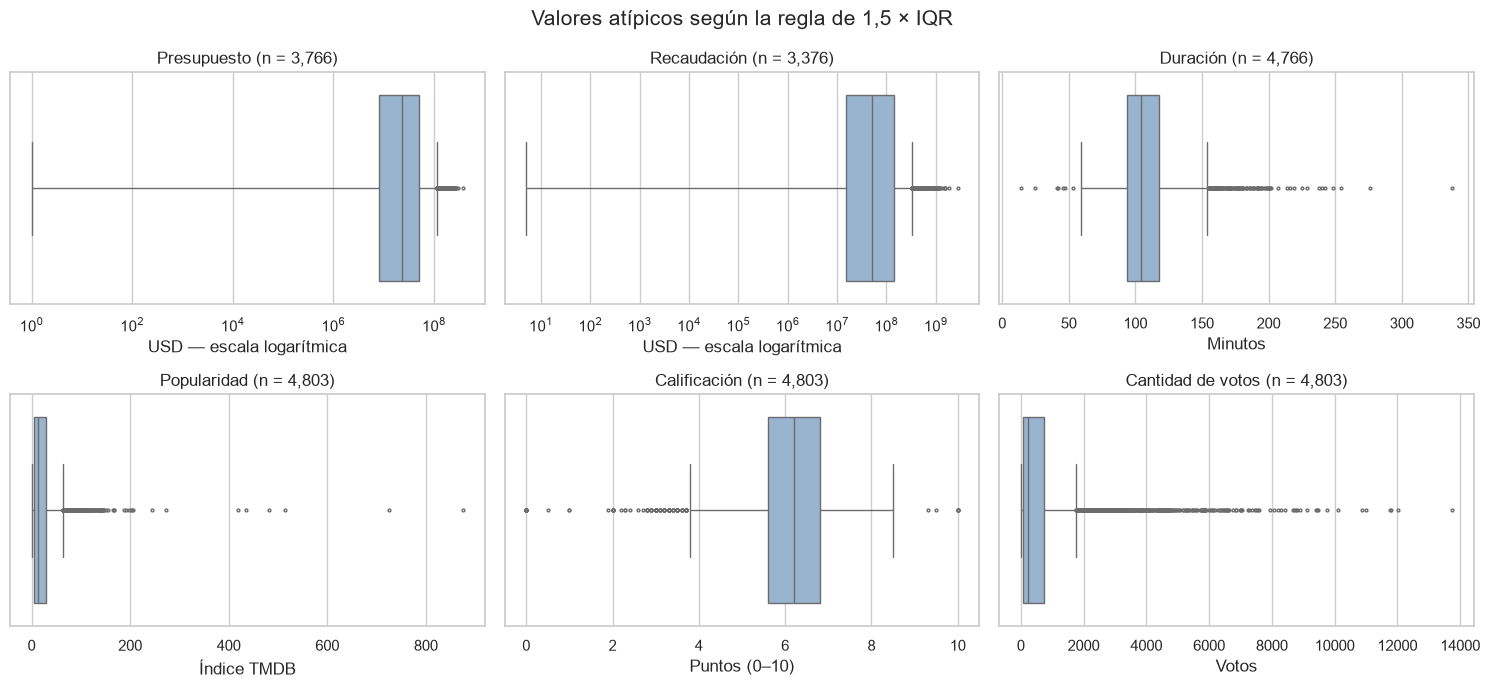

,variable,extremo,id,título,valor
0,budget,superior,1865,Pirates of the Caribbean: On Stranger Tides,3.800000e+08
1,budget,superior,285,Pirates of the Caribbean: At World's End,3.000000e+08
2,budget,superior,99861,Avengers: Age of Ultron,2.800000e+08
3,revenue,superior,19995,Avatar,2.787965e+09
4,revenue,superior,597,Titanic,1.845034e+09
5,revenue,superior,24428,The Avengers,1.519558e+09
6,runtime,inferior,211557,Vessel,1.400000e+01
7,runtime,inferior,13187,A Charlie Brown Christmas,2.500000e+01
8,runtime,inferior,78394,Sea Rex 3D: Journey to a Prehistoric World,4.100000e+01
9,runtime,superior,43434,Carlos,3.380000e+02


In [9]:
variables_iqr = {
    "budget": ("Presupuesto", "USD"),
    "revenue": ("Recaudación", "USD"),
    "runtime": ("Duración", "Minutos"),
    "popularity": ("Popularidad", "Índice TMDB"),
    "vote_average": ("Calificación", "Puntos (0–10)"),
    "vote_count": ("Cantidad de votos", "Votos"),
}
series_iqr, limites_iqr, casos_iqr = {}, [], []
for variable in variables_iqr:
    serie = numericas.loc[np.isfinite(numericas[variable]), variable]
    if variable in variables_cero:
        serie = serie[serie > 0]
    series_iqr[variable] = serie
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fuera = (serie < inferior) | (serie > superior)
    limites_iqr.append({"variable": variable, "n_evaluados": len(serie),
                        "Q1": q1, "Q3": q3, "IQR": iqr,
                        "límite_inferior": inferior, "límite_superior": superior,
                        "señalados": int(fuera.sum()),
                        "% señalados": fuera.mean() * 100})
    # Mostramos hasta tres ejemplos de cada extremo para revisar películas concretas.
    for extremo, seleccion in [("inferior", serie[serie < inferior].nsmallest(3)),
                               ("superior", serie[serie > superior].nlargest(3))]:
        for indice, valor in seleccion.items():
            casos_iqr.append({"variable": variable, "extremo": extremo,
                              "id": movies.at[indice, "id"], "título": movies.at[indice, "title"],
                              "valor": valor})

resumen_iqr = pd.DataFrame(limites_iqr).set_index("variable")
display(resumen_iqr.round(2))

fig, ejes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (variable, (titulo, unidad)) in zip(ejes.flat, variables_iqr.items()):
    sns.boxplot(x=series_iqr[variable], ax=ax, color="#90b4d8", fliersize=2)
    ax.set_title(f"{titulo} (n = {len(series_iqr[variable]):,})")
    if variable in ["budget", "revenue"]:
        ax.set_xscale("log")
        unidad += " — escala logarítmica"
    ax.set_xlabel(unidad)
    ax.set_ylabel("")
fig.suptitle("Valores atípicos según la regla de 1,5 × IQR", fontsize=15)
plt.tight_layout()
plt.show()

display(pd.DataFrame(casos_iqr))

**Interpretación.** La regla señala 245 presupuestos, 299 recaudaciones y 147 duraciones dentro de sus respectivos universos positivos. Entre las recaudaciones altas aparecen *Avatar* y *Titanic*: su posición extrema no prueba que el dato esté mal. Eliminarlas automáticamente cambiaría precisamente el desempeño comercial que buscamos estudiar.

En duración encontramos casos como *Carlos* (338 minutos), que ameritan revisar el tipo de producción y la versión registrada antes de decidir si son comparables. Una duración corta tampoco es necesariamente incorrecta. Para calificaciones y votos debemos considerar la cantidad de evaluaciones: una puntuación extrema con pocos votos aporta evidencia limitada.

Proponemos conservar los atípicos mientras no exista una justificación documentada para corregirlos o excluirlos. Los límites IQR financieros inferiores son negativos, por lo que esta regla no detecta presupuestos positivos sospechosamente pequeños; por eso hacemos una revisión adicional.

### 1.7 Revisión del filtro provisional de USD 10.000

En la exploración del proyecto se planteó usar un monto mínimo de USD 10.000 tanto para presupuesto como para recaudación. Ese umbral es una decisión analítica provisional; no es una regla del dataset ni una consecuencia del IQR.

Primero identificamos las películas estrenadas con ambos montos positivos y finitos. Luego listamos los casos que el umbral dejaría fuera y comparamos la distribución de `revenue / budget` antes y después. Esta comparación describe la sensibilidad del diagnóstico al filtro; todavía no fija la población definitiva ni valida hipótesis.

In [10]:
MONTO_MINIMO_DIAGNOSTICO = 10_000
estrenadas = movies["status"].eq("Released").fillna(False)
montos_positivos = (numericas[["budget", "revenue"]].gt(0)
                    & np.isfinite(numericas[["budget", "revenue"]])).all(axis=1)
base_financiera = estrenadas & montos_positivos
monto_pequeno = (numericas[["budget", "revenue"]] < MONTO_MINIMO_DIAGNOSTICO).any(axis=1)
casos_monto_pequeno = base_financiera & monto_pequeno
con_umbral = base_financiera & ~monto_pequeno

display(pd.Series({
    "Todas las películas": N,
    "Con estado Released": int(estrenadas.sum()),
    "Released con presupuesto y recaudación positivos": int(base_financiera.sum()),
    "De las anteriores, algún monto menor a USD 10.000": int(casos_monto_pequeno.sum()),
    "Released con ambos montos de al menos USD 10.000": int(con_umbral.sum()),
}, name="películas").to_frame())
display(movies.loc[casos_monto_pequeno,
                   ["id", "title", "release_date", "budget", "revenue"]].sort_values("budget"))

sensibilidad = []
for nombre, mascara in [("Ambos montos positivos", base_financiera),
                        ("Ambos montos >= USD 10.000", con_umbral)]:
    multiplicador_aux = numericas.loc[mascara, "revenue"] / numericas.loc[mascara, "budget"]
    sensibilidad.append({"escenario": nombre, "películas": int(mascara.sum()),
                         "multiplicador_mediano": multiplicador_aux.median(),
                         "multiplicador_promedio": multiplicador_aux.mean(),
                         "multiplicador_máximo": multiplicador_aux.max()})
display(pd.DataFrame(sensibilidad).set_index("escenario").round(3))

,películas
Todas las películas,4803
Con estado Released,4795
Released con presupuesto y recaudación positivos,3228
"De las anteriores, algún monto menor a USD 10.000",24
Released con ambos montos de al menos USD 10.000,3204


,id,title,release_date,budget,revenue
4238,3082,Modern Times,1936-02-05,1,8500000
3611,22649,A Farewell to Arms,1932-12-08,4,25
3419,38415,Bran Nue Dae,2009-08-09,7,7
3372,13006,Split Second,1992-05-01,7,5
4608,11980,The Prophecy,1995-09-01,8,16
3137,78383,Nurse 3-D,2013-09-28,10,10000000
3131,217708,Of Horses and Men,2013-08-30,10,11
2933,28932,F.I.S.T.,1978-04-26,11,11
1912,10397,Angela's Ashes,1999-12-25,25,13
1771,1613,The 51st State,2001-12-07,28,14


,películas,multiplicador_mediano,multiplicador_promedio,multiplicador_máximo
escenario,,,,
Ambos montos positivos,3228,2.300,2955.738,8500000.000
Ambos montos >= USD 10.000,3204,2.306,11.128,12890.387


In [11]:
sin_filtro, con_filtro = sensibilidad
display(Markdown(
    f"**Interpretación.** El umbral dejaría fuera **{casos_monto_pequeno.sum():,} películas**, "
    f"el **{casos_monto_pequeno.sum() / base_financiera.sum():.2%}** de las estrenadas con ambos montos positivos. "
    f"El multiplicador mediano pasa de **{sin_filtro['multiplicador_mediano']:.3f}x** "
    f"a **{con_filtro['multiplicador_mediano']:.3f}x**, mientras el promedio pasa de "
    f"**{sin_filtro['multiplicador_promedio']:.3f}x** a **{con_filtro['multiplicador_promedio']:.3f}x**. "
    "La comparación permite ver por qué el porcentaje de filas retiradas no basta para evaluar el efecto del filtro. "
    "Los presupuestos muy pequeños pueden producir cocientes enormes."
))

**Interpretación.** El umbral dejaría fuera **24 películas**, el **0.74%** de las estrenadas con ambos montos positivos. El multiplicador mediano pasa de **2.300x** a **2.306x**, mientras el promedio pasa de **2955.738x** a **11.128x**. La comparación permite ver por qué el porcentaje de filas retiradas no basta para evaluar el efecto del filtro. Los presupuestos muy pequeños pueden producir cocientes enormes.

Entre los casos hay presupuestos de 1, 4 o 7 dólares y recaudaciones muy pequeñas. Son señales para revisar, pero con este archivo no podemos afirmar qué monto era el correcto ni multiplicarlo por un millón suponiendo un error de unidad. El umbral también puede excluir producciones de bajo presupuesto o películas con recaudaciones reducidas que sí sean válidas.

Proponemos revisar la evidencia de cada caso, documentar cualquier decisión y conservar esta comparación de sensibilidad. Si no podemos verificar el monto, debe quedar marcado como dudoso o mantenerse una comparación entre escenarios. Retirar una película del análisis financiero no exige retirarla de todos los análisis descriptivos.

### 1.8 Decisiones propuestas para la limpieza

Consolidamos las recomendaciones para la siguiente etapa. La población útil depende de la pregunta: una película puede servir para contar estrenos y no para calcular retorno. Por eso proponemos registrar los motivos de exclusión y mantener el conteo de películas que queda para cada análisis.

| Problema o revisión | Evidencia del diagnóstico | Efecto sobre el análisis | Tratamiento propuesto |
|---|---|---|---|
| Presupuesto o recaudación cero | 1.037 y 1.427 registros, respectivamente; pueden solaparse | Retornos indefinidos o pérdidas aparentes | Tratar como no reportados para análisis financiero y definir elegibilidad con ambos montos positivos; conservar para otros usos cuando proceda. |
| Duración cero o nula | 35 ceros y dos nulos | Comparaciones de duración distorsionadas | Proponer ceros como faltantes y excluirlos solo de los análisis que necesitan duración; no imputar una duración sin justificación. |
| Fecha ausente | Una película; ninguna fecha presente inválida | No permite ubicar el estreno en el tiempo | Mantener el registro para análisis que no necesitan fecha; dejarlo fuera de análisis temporales. |
| Estado diferente de Released | Cinco Rumored y tres Post Production | Desempeño observado no comparable al de películas estrenadas | Separar del análisis de desempeño de estrenadas. |
| Listas vacías | Géneros, productoras, países, idiomas, reparto y equipo técnico | Segmentaciones incompletas | Identificar como sin información; no inventar categorías ni personas y definir elegibilidad por análisis. |
| Duplicados e identificadores | No encontramos llaves repetidas ni identificadores sin correspondencia | La unión actual puede ser uno a uno | Conservar las filas y validar cardinalidad y conteos al unir; no deduplicar por título. |
| Atípicos por IQR | Valores señalados en las seis variables revisadas | Sensibilidad de promedios y comparaciones | Revisar casos concretos y conservar los valores plausibles; no eliminar ni recortar automáticamente. |
| Montos positivos menores a USD 10.000 | 24 casos en la base financiera provisional | Cocientes extremos o exclusión de casos válidos | Revisar evidencia y documentar decisiones; comparar resultados con y sin umbral. |
| Cero votos y calificaciones extremas | 62 películas sin votos; calificaciones que deben leerse con su cantidad de votos | Evaluaciones poco informativas | Definir después el criterio de uso de calificaciones y reportar su soporte; no confundir cero votos con mala recepción. |
| Faltantes en campos descriptivos | Página web, frase promocional y sinopsis | Limitan algunos usos, pero no necesariamente el financiero | Evitar la eliminación global de filas por cualquier nulo. |

**Cierre.** La cobertura de las llaves permite integrar películas y créditos sin pérdida de identificadores en los archivos actuales. La principal limitación para el retorno son los montos no reportados y los casos financieros dudosos. La base de películas con cifras disponibles puede representar de manera desigual a las producciones, por lo que debemos declarar a qué población aplican los resultados. Dejamos las decisiones definitivas y su aplicación para la sección de limpieza.

In [12]:
# Verificamos que las conversiones y filtros auxiliares no cambiaron las tablas cargadas.
pd.testing.assert_frame_equal(movies, movies_original)
pd.testing.assert_frame_equal(credits, credits_original)
assert int(base_financiera.sum()) == int(casos_monto_pequeno.sum() + con_umbral.sum())
assert resumen_json[estados].sum(axis=1).eq(N).all()
print("Diagnóstico terminado: tablas originales intactas y conteos internos consistentes.")

Diagnóstico terminado: tablas originales intactas y conteos internos consistentes.


## 2. Limpieza y tratamiento de los datos

En esta sección aplicamos las decisiones que propusimos en la sección 1.8. La idea que guía toda la limpieza es la misma que salió del diagnóstico: **la población útil depende de la pregunta**. Una película sin presupuesto reportado no sirve para calcular retorno, pero sí para contar estrenos por año o para ver qué géneros se producen más. Por eso no borramos filas de forma global: corregimos lo que se puede corregir, convertimos los faltantes disfrazados en faltantes reales y marcamos con columnas indicadoras qué películas entran en cada tipo de análisis.

Trabajamos sobre una copia (`peliculas`) para que las tablas originales cargadas en la sección 1 sigan intactas, como lo verificamos al final del diagnóstico. Todo lo que hagamos aquí se puede rastrear hasta una decisión documentada.

### 2.1 Tipos de datos y columnas en formato JSON

Las columnas `genres`, `keywords`, `production_companies`, `production_countries` y `spoken_languages` vienen como texto con una lista de diccionarios en JSON, por ejemplo `[{"id": 28, "name": "Action"}, ...]`. Para analizarlas solo necesitamos los nombres, así que las convertimos en listas de nombres con `json.loads`. En el diagnóstico (sección 1.3) comprobamos que las siete columnas tienen JSON válido, así que la conversión no debería fallar en ninguna fila; si una lista está vacía, queda como lista vacía y no inventamos ningún valor.

También pasamos `release_date` de texto a fecha con `pd.to_datetime`, usando el formato `AAAA-MM-DD` que ya validamos. La única fecha ausente queda como `NaT` (el faltante de fechas en pandas).

In [13]:
peliculas = movies.copy()

def nombres(texto_json):
    # Convierte el texto JSON en una lista con el campo "name" de cada elemento
    if pd.isna(texto_json) or not str(texto_json).strip():
        return []
    return [elemento["name"] for elemento in json.loads(texto_json)]

for columna in json_movies:
    peliculas[columna] = peliculas[columna].apply(nombres)

peliculas["release_date"] = pd.to_datetime(peliculas["release_date"], format="%Y-%m-%d", errors="coerce")

display(peliculas.loc[[0, 1], ["title", "genres", "production_countries", "release_date"]])
display(pd.Series({
    "Fechas convertidas": int(peliculas["release_date"].notna().sum()),
    "Fechas faltantes (NaT)": int(peliculas["release_date"].isna().sum()),
    "Películas con lista de géneros vacía": int(peliculas["genres"].str.len().eq(0).sum()),
}, name="películas").to_frame())

,title,genres,production_countries,release_date
0,Avatar,"[Action, Adventure, Fantasy, Science Fiction]","[United States of America, United Kingdom]",2009-12-10
1,Pirates of the Caribbean: At World's End,"[Adventure, Fantasy, Action]",[United States of America],2007-05-19


,películas
Fechas convertidas,4802
Fechas faltantes (NaT),1
Películas con lista de géneros vacía,28


**Interpretación.** Ahora cada película tiene sus géneros, países, productoras e idiomas como listas de nombres que se pueden contar y filtrar, y la fecha de estreno es una fecha de verdad, con la que podemos sacar año, mes o década en el siguiente paso. Las listas vacías (28 en géneros) se mantienen: esas películas no salen del proyecto, solo no van a aparecer cuando segmentemos por género.

### 2.2 Faltantes disfrazados: ceros en montos, duración y votos

El diagnóstico mostró que un presupuesto o una recaudación en 0 no significan que la película fue gratis o que no vendió nada, sino que **nadie reportó el dato**. Lo mismo pasa con una duración de 0 minutos. Si dejamos esos ceros, cualquier promedio sale distorsionado y el retorno (`revenue / budget`) se vuelve una división por cero o una pérdida falsa del 100 %. Por eso los reemplazamos por `NaN`, que es como pandas representa un dato faltante: así las funciones como `mean()` o `median()` los ignoran automáticamente en lugar de contarlos como ceros.

No los imputamos (no los rellenamos con la mediana ni con otro valor), porque inventar el presupuesto de mil películas cambiaría justamente lo que queremos medir. Como vimos en la guía de la semana 3, imputar tiene sentido cuando el faltante es poco y la variable no es el centro del análisis; aquí es al revés.

Hacemos lo mismo con la calificación de las 62 películas que tienen **cero votos**: su `vote_average` aparece como 0, pero ese 0 no es una mala calificación, es que nadie votó. Dejarlo así haría ver peor a esas películas en cualquier promedio. La película con un solo voto y calificación 0 sí la dejamos, porque ese voto existe; la confiabilidad de las calificaciones con pocos votos se trata al definir las variables.

In [14]:
antes = pd.DataFrame({
    "ceros_antes": peliculas[["budget", "revenue", "runtime"]].eq(0).sum(),
    "nulos_antes": peliculas[["budget", "revenue", "runtime"]].isna().sum(),
})

for columna in ["budget", "revenue", "runtime"]:
    peliculas[columna] = peliculas[columna].replace(0, np.nan)

sin_votos = peliculas["vote_count"].eq(0)
peliculas.loc[sin_votos, "vote_average"] = np.nan

antes["ceros_después"] = peliculas[["budget", "revenue", "runtime"]].eq(0).sum()
antes["nulos_después"] = peliculas[["budget", "revenue", "runtime"]].isna().sum()
display(antes)
print(f"Calificaciones pasadas a faltante por tener cero votos: {sin_votos.sum()}")

,ceros_antes,nulos_antes,ceros_después,nulos_después
budget,1037,0,0,1037
revenue,1427,0,0,1427
runtime,35,2,0,37


Calificaciones pasadas a faltante por tener cero votos: 62


**Interpretación.** Los 1.037 presupuestos, 1.427 recaudaciones y 35 duraciones en cero quedaron como faltantes (en duración se suman a los dos nulos que ya existían, para un total de 37). Ningún cero quedó en estas columnas. A partir de aquí, cuando calculemos una mediana de presupuesto, se calcula solo con las películas que sí lo reportaron, que es lo correcto.

### 2.3 Unión con los créditos y extracción del director

Para responder preguntas sobre talento necesitamos saber quién dirigió cada película. Esa información está en la columna `crew` del archivo de créditos, que es una lista JSON con todo el equipo técnico (productores, guionistas, fotógrafos, etc.). Nos quedamos solo con las personas cuyo cargo (`job`) es `Director`.

Unimos las dos tablas por `id` y `movie_id`. Usamos `validate="one_to_one"`, como lo recomendó el diagnóstico (sección 1.4): si alguna película apareciera dos veces en cualquiera de las tablas, pandas detendría la unión con un error en lugar de duplicar filas sin que nos diéramos cuenta. Hacemos una unión `left` para que ninguna película se pierda aunque no tenga créditos.

In [15]:
def directores(crew_json):
    # Devuelve la lista de nombres cuyo cargo es Director
    return [persona["name"] for persona in json.loads(crew_json) if persona.get("job") == "Director"]

creditos = credits[["movie_id"]].copy()
creditos["directores"] = credits["crew"].apply(directores)

filas_antes = len(peliculas)
peliculas = peliculas.merge(creditos, left_on="id", right_on="movie_id",
                            how="left", validate="one_to_one").drop(columns="movie_id")
assert len(peliculas) == filas_antes, "La unión cambió el número de películas"

numero_directores = peliculas["directores"].str.len()
display(numero_directores.value_counts().sort_index()
        .rename_axis("directores por película").rename("películas").to_frame().T)
display(peliculas.loc[numero_directores >= 2, ["title", "directores"]].head(4))

directores por película,0,1,2,3,4,6,7,8,12,21
películas,30,4465,277,21,3,2,1,1,2,1


,title,directores
6,Tangled,"[Byron Howard, Nathan Greno]"
26,Captain America: Civil War,"[Anthony Russo, Joe Russo]"
40,Cars 2,"[John Lasseter, Brad Lewis]"
55,Brave,"[Brenda Chapman, Mark Andrews, Steve Purcell]"


**Interpretación.** La unión conservó las 4.803 películas, sin duplicar ninguna. La gran mayoría (4.465) tiene un solo director; 277 tienen dos, que suele ser el caso de duplas de directores o de películas animadas, y unas pocas tienen muchos, como las películas por episodios. Treinta películas no tienen ningún director registrado: no las sacamos del proyecto, simplemente no van a entrar en el análisis de talento. Guardamos la lista completa de directores y dejamos para el siguiente paso la decisión de cómo resumirla en una sola variable.

### 2.4 Población de cada análisis

Aquí aplicamos el resto de las decisiones de la sección 1.8, pero en lugar de eliminar filas creamos **columnas indicadoras** (verdadero o falso) que dicen si cada película sirve para cierto tipo de análisis:

- **`estrenada`**: el estado es `Released`. Las cinco películas en `Rumored` y las tres en `Post Production` no tienen un desempeño comercial comparable, así que no entran al análisis de desempeño.
- **`monto_dudoso`**: algún monto reportado es menor a USD 10.000. En el diagnóstico (sección 1.7) revisamos los 24 casos que están dentro de las estrenadas con ambos montos reportados: presupuestos de 1, 4 o 7 dólares y recaudaciones mínimas, que en su mayoría parecen errores de digitación. Aquí la marca se aplica a todo el archivo, así que también cae en películas que solo reportaron uno de los dos montos. No podemos saber cuál era el valor correcto, así que no los corregimos: los marcamos. La comparación de sensibilidad de la sección 1.7 muestra por qué no podemos dejarlos en el análisis financiero: con ellos el multiplicador promedio es de 2.955x y sin ellos de 11x, mientras que la mediana casi no cambia (2,30x contra 2,31x). Una sola fila con presupuesto de 1 dólar arrastra cualquier promedio.
- **`base_financiera`**: estrenada, con presupuesto y recaudación reportados y sin monto dudoso. Es la población para todo lo que use dinero: retorno, rentabilidad, KPIs financieros y las hipótesis.

Los valores atípicos que señaló el IQR (*Avatar*, *Titanic*, duraciones como la de *Carlos*) **no se modifican ni se eliminan**: como concluimos en el diagnóstico, son películas reales y extremas, y quitarlas cambiaría justamente el desempeño comercial que queremos estudiar.

In [16]:
MONTO_MINIMO = 10_000

peliculas["estrenada"] = peliculas["status"].eq("Released")
peliculas["monto_dudoso"] = peliculas["budget"].lt(MONTO_MINIMO) | peliculas["revenue"].lt(MONTO_MINIMO)
peliculas["base_financiera"] = (peliculas["estrenada"]
                                & peliculas["budget"].notna()
                                & peliculas["revenue"].notna()
                                & ~peliculas["monto_dudoso"])

poblaciones = pd.Series({
    "Todas las películas": len(peliculas),
    "Estrenadas (desempeño comercial)": peliculas["estrenada"].sum(),
    "Con fecha de estreno (análisis en el tiempo)": peliculas["release_date"].notna().sum(),
    "Con duración reportada": peliculas["runtime"].notna().sum(),
    "Con al menos un género (segmentación por género)": peliculas["genres"].str.len().gt(0).sum(),
    "Con al menos un director (análisis de talento)": peliculas["directores"].str.len().gt(0).sum(),
    "Con calificación (al menos un voto)": peliculas["vote_average"].notna().sum(),
    "Con algún monto dudoso (< USD 10.000)": peliculas["monto_dudoso"].sum(),
    "Base financiera (retorno, KPIs e hipótesis)": peliculas["base_financiera"].sum(),
}, name="películas").astype(int).to_frame()
poblaciones["% del total"] = (poblaciones["películas"] / len(peliculas) * 100).round(2)
display(poblaciones)

,películas,% del total
Todas las películas,4803,100.00
Estrenadas (desempeño comercial),4795,99.83
Con fecha de estreno (análisis en el tiempo),4802,99.98
Con duración reportada,4766,99.23
Con al menos un género (segmentación por género),4775,99.42
Con al menos un director (análisis de talento),4773,99.38
Con calificación (al menos un voto),4741,98.71
Con algún monto dudoso (< USD 10.000),52,1.08
"Base financiera (retorno, KPIs e hipótesis)",3204,66.71


**Interpretación.** Ninguna película salió del archivo: las 4.803 siguen ahí, y cada análisis va a tomar la población que le corresponde. La marca de monto dudoso queda en 52 películas: las 24 del diagnóstico más las que tienen un solo monto reportado y es menor a USD 10.000, que de todas formas no entraban en la base financiera porque les falta el otro monto. Lo más importante de esta tabla es la última fila: **3.204 películas (el 66,71 %) forman la base financiera**. Es la misma cifra con la que exploramos las hipótesis en el notebook 03 y con la que planteamos el problema en el notebook 01, así que todos los análisis financieros del proyecto parten de la misma base.

Esto también deja clara una limitación que hay que repetir en las conclusiones: un tercio de las películas no entra en el análisis de retorno, y no es un tercio al azar. Las películas que reportan cifras de taquilla tienden a ser las más comerciales, así que lo que concluyamos sobre rentabilidad aplica a ese tipo de producciones.

### 2.5 Verificación y exportación

Antes de guardar comprobamos que la limpieza no rompió nada: que siguen todas las películas, que no hay identificadores repetidos, que en la base financiera ningún presupuesto es cero o faltante (para que el retorno se pueda calcular sin divisiones por cero) y que las tablas originales siguen intactas.

Para exportar, las listas se guardan como texto separado por `|` (por ejemplo `Action|Adventure|Fantasy`). Elegimos ese formato porque el CSV no tiene un tipo de dato "lista", y el separador `|` no aparece en los nombres de géneros, países o directores, a diferencia de la coma. Power BI y pandas pueden volver a separarlo cuando lo necesiten. De los créditos solo traemos los directores: el reparto y el equipo técnico completos (`cast` y `crew`) pesan mucho y no los necesitamos. El resto de columnas de películas se conserva, porque la selección de variables se hace en el siguiente paso.

In [17]:
base = peliculas[peliculas["base_financiera"]]
assert len(peliculas) == N, "Se perdieron películas en la limpieza"
assert peliculas["id"].is_unique, "Hay identificadores repetidos"
assert base["budget"].gt(0).all() and base["revenue"].gt(0).all(), "Hay montos inválidos en la base financiera"
pd.testing.assert_frame_equal(movies, movies_original)
pd.testing.assert_frame_equal(credits, credits_original)

columnas_lista = json_movies + ["directores"]
exportar = peliculas.copy()
for columna in columnas_lista:
    exportar[columna] = exportar[columna].str.join("|")

PROCESSED = RAW.parent / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)
ruta_salida = PROCESSED / "peliculas_limpias.csv"
exportar.to_csv(ruta_salida, index=False)

print(f"Archivo guardado: data/processed/{ruta_salida.name}")
print(f"Filas: {len(exportar):,} | Columnas: {exportar.shape[1]}")
print(f"Base financiera: {int(exportar['base_financiera'].sum()):,} películas")

Archivo guardado: data/processed/peliculas_limpias.csv
Filas: 4,803 | Columnas: 24
Base financiera: 3,204 películas


### 2.6 Resumen de la limpieza

| Problema | Qué hicimos | Por qué |
|---|---|---|
| Columnas JSON | Convertidas a listas de nombres (`json.loads`) | Permiten contar y segmentar por género, país, productora e idioma |
| Fecha como texto | Convertida a fecha; la única ausente queda como `NaT` | Necesitamos año, mes y década para el análisis en el tiempo |
| Ceros en presupuesto, recaudación y duración | Reemplazados por `NaN`, sin imputar | Son datos no reportados; como ceros distorsionan promedios y retornos |
| Calificación de películas sin votos | Pasada a `NaN` (62 películas) | Un 0 sin votos no es una mala calificación |
| Director | Extraído de `crew` y unido con `validate="one_to_one"` | Base del análisis de talento, sin riesgo de duplicar películas |
| Películas no estrenadas | Marcadas con `estrenada = False` | Su desempeño no es comparable |
| Montos menores a USD 10.000 | Marcados con `monto_dudoso` y fuera de la base financiera | Errores probables que disparan el promedio del retorno |
| Valores atípicos | Conservados sin cambios | Son películas reales; quitarlas cambiaría lo que queremos estudiar |
| Filas eliminadas | Ninguna | Cada análisis usa su propia población mediante las columnas indicadoras |

El resultado queda en `data/processed/peliculas_limpias.csv`, con las 4.803 películas, las columnas convertidas, el director y las tres columnas indicadoras. Sobre este archivo se crean las variables derivadas (ganancia, multiplicador, rentable, año, género principal) en el siguiente paso.